# Tugas - Klasifikasi dengan Artificial Neural Network (ANN)

| Nama | NRP |
|------|-----|
| Daffa Aufa Afif | 5054251022 |

## Deskripsi Tugas
Membangun model `MLPClassifier` untuk memprediksi pelanggan yang berhenti berlangganan (*churn*) menggunakan dataset Telco Customer Churn. Eksperimen membandingkan fungsi aktivasi, ukuran arsitektur, dan jumlah iterasi. Data test dipakai untuk evaluasi akhir setelah konfigurasi dipilih dari validasi.

# 1. Persiapan Dataset dan Eksplorasi Awal

In [1]:
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from scipy.stats import chi2_contingency
from sklearn.compose import ColumnTransformer
from sklearn.exceptions import ConvergenceWarning
from sklearn.impute import SimpleImputer
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

RANDOM_STATE = 42
# Iterasi aktual dan kurva loss tetap diperiksa pada bagian evaluasi.
warnings.filterwarnings("ignore", category=ConvergenceWarning)

In [2]:
nama_file = "WA_Fn-UseC_-Telco-Customer-Churn.csv"
data_path = Path(nama_file)
if not data_path.exists():
    data_path = Path("/media/dff/Elements1/Codex/Works/ANN") / nama_file
if not data_path.exists():
    raise FileNotFoundError(f"Dataset tidak ditemukan: {nama_file}")

df = pd.read_csv(data_path)
print("Ukuran data:", df.shape)
print("\n5 data awal:")
display(df.head())
print("\nInformasi kolom:")
df.info()
print("\nStatistik deskriptif:")
display(df.describe(include="all").T)
print("\nMissing value mentah:")
print(df.isna().sum())
print("Duplikat seluruh baris:", df.duplicated().sum())
print("TotalCharges berupa string kosong:", df["TotalCharges"].astype(str).str.strip().eq("").sum())

Ukuran data: (7043, 21)

5 data awal:


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes



Informasi kolom:
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   s

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customerID,7043,7043,7590-VHVEG,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,7043,2,Male,3555,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SeniorCitizen,7043.0,NaN,NaN,NaN,0.162147,0.368612,0.0,0.0,0.0,0.0,1.0
Partner,7043,2,No,3641,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dependents,7043,2,No,4933,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tenure,7043.0,NaN,NaN,NaN,32.371149,24.559481,0.0,9.0,29.0,55.0,72.0
PhoneService,7043,2,Yes,6361,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MultipleLines,7043,3,No,3390,NaN,NaN,NaN,NaN,NaN,NaN,NaN
InternetService,7043,3,Fiber optic,3096,NaN,NaN,NaN,NaN,NaN,NaN,NaN
OnlineSecurity,7043,3,No,3498,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Missing value mentah:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64
Duplikat seluruh baris: 0
TotalCharges berupa string kosong: 11


Data memiliki 7.043 baris dan 21 kolom. Tidak ada baris yang duplikat secara persis. Kolom `TotalCharges` bertipe teks karena 11 baris berisi string kosong, sehingga jumlah `NaN` awal belum menunjukkan masalah tersebut.

In [3]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print("Missing value setelah konversi:")
print(df.isna().sum()[lambda s: s > 0])

numeric_features = ["tenure", "MonthlyCharges", "TotalCharges"]
categorical_features = [c for c in df.columns
                        if c not in numeric_features + ["customerID", "Churn"]]
print("Fitur numerik:", numeric_features)
print("Jumlah fitur kategorikal:", len(categorical_features))

Missing value setelah konversi:
TotalCharges    11
dtype: int64
Fitur numerik: ['tenure', 'MonthlyCharges', 'TotalCharges']
Jumlah fitur kategorikal: 16


Distribusi kelas:
Churn
No     5174
Yes    1869
Name: count, dtype: int64
Persentase kelas:
Churn
No     73.46
Yes    26.54
Name: count, dtype: float64


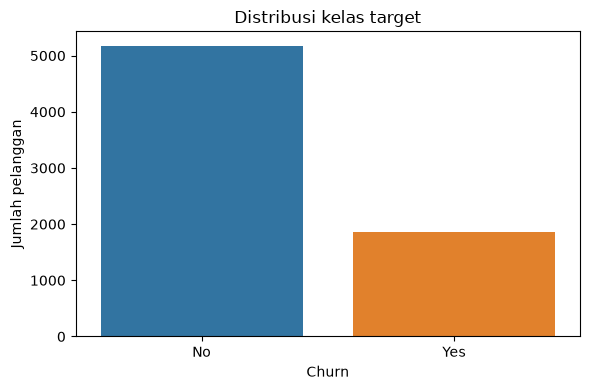

In [4]:
jumlah_kelas = df["Churn"].value_counts().reindex(["No", "Yes"])
print("Distribusi kelas:")
print(jumlah_kelas)
print("Persentase kelas:")
print((jumlah_kelas / len(df) * 100).round(2))

plt.figure(figsize=(6, 4))
sns.barplot(x=jumlah_kelas.index, y=jumlah_kelas.values,
            hue=jumlah_kelas.index, legend=False)
plt.xlabel("Churn")
plt.ylabel("Jumlah pelanggan")
plt.title("Distribusi kelas target")
plt.tight_layout()
plt.show()

Kelas `No` lebih banyak daripada `Yes` (73,46% berbanding 26,54%). Karena itu, akurasi saja belum cukup untuk menilai kemampuan model mengenali pelanggan yang benar-benar churn.

## EDA tambahan

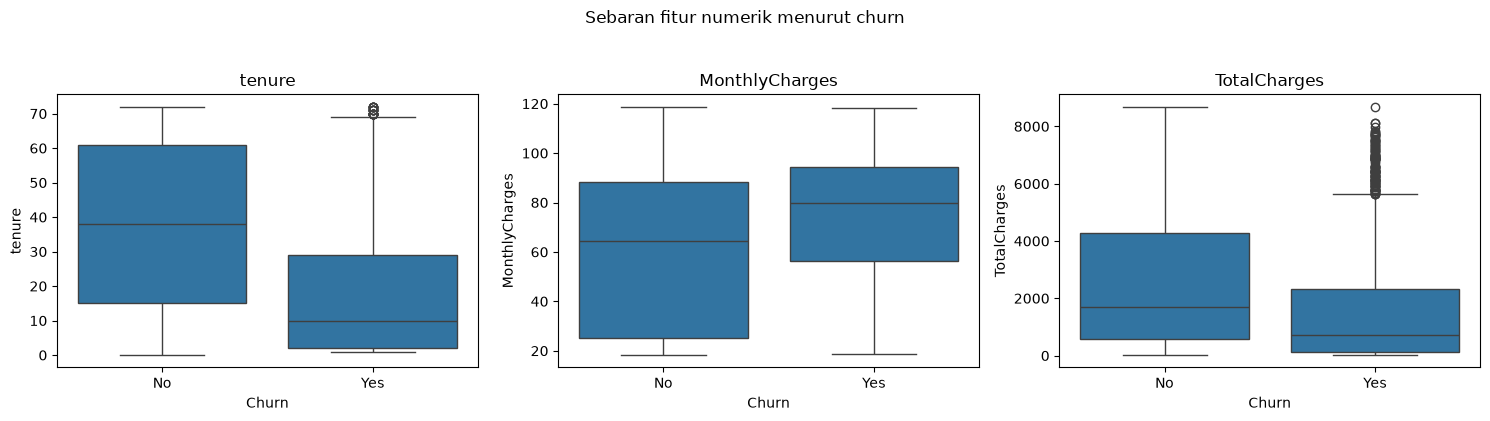

Median fitur numerik menurut Churn:


,tenure,MonthlyCharges,TotalCharges
Churn,,,
No,38.0,64.43,1683.60
Yes,10.0,79.65,703.55


In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, fitur in zip(axes, numeric_features):
    sns.boxplot(data=df, x="Churn", y=fitur, order=["No", "Yes"], ax=ax)
    ax.set_title(fitur)
plt.suptitle("Sebaran fitur numerik menurut churn", y=1.04)
plt.tight_layout()
plt.show()

print("Median fitur numerik menurut Churn:")
display(df.groupby("Churn")[numeric_features].median().round(2))

Korelasi Spearman dengan Churn=Yes:
tenure           -0.367
TotalCharges     -0.232
MonthlyCharges    0.185
dtype: float64


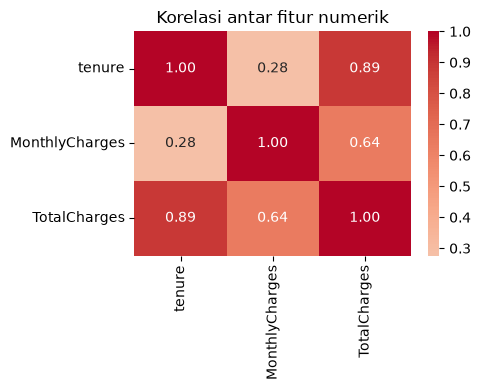

In [6]:
target_angka = df["Churn"].eq("Yes").astype(int)
korelasi_target = df[numeric_features].corrwith(target_angka, method="spearman")
print("Korelasi Spearman dengan Churn=Yes:")
print(korelasi_target.sort_values(key=abs, ascending=False).round(3))

plt.figure(figsize=(5, 4))
sns.heatmap(df[numeric_features].corr(method="spearman"),
            annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Korelasi antar fitur numerik")
plt.tight_layout()
plt.show()

Median `tenure` pelanggan churn lebih rendah daripada pelanggan yang bertahan, sedangkan median `MonthlyCharges` lebih tinggi. Korelasi Spearman dengan label paling besar secara absolut ada pada `tenure`. Ini hubungan satu fitur dengan target, belum berarti fitur lain tidak berguna bagi ANN.

Hubungan fitur kategorikal dengan Churn:
Contract            0.410
OnlineSecurity      0.347
TechSupport         0.343
InternetService     0.322
PaymentMethod       0.303
OnlineBackup        0.292
DeviceProtection    0.282
StreamingMovies     0.231
StreamingTV         0.231
PaperlessBilling    0.192
Dependents          0.164
SeniorCitizen       0.151
Partner             0.150
MultipleLines       0.040
PhoneService        0.012
gender              0.009
Name: Cramer's V, dtype: float64


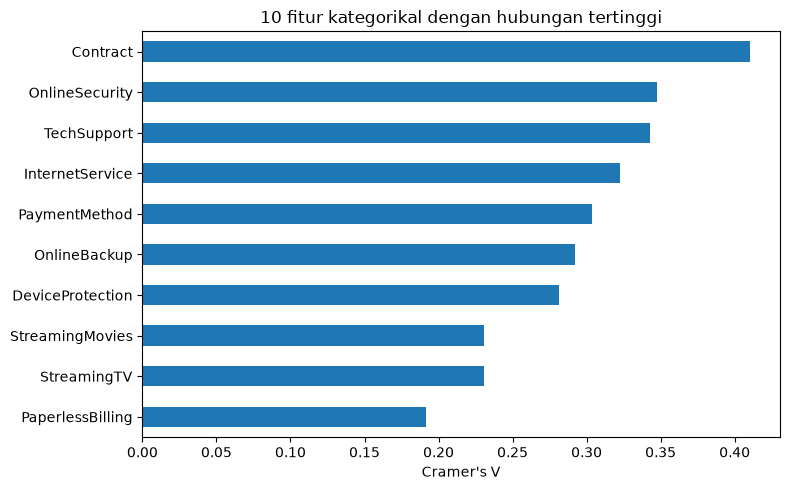

In [7]:
def cramers_v(fitur, target):
    tabel = pd.crosstab(fitur, target)
    chi2 = chi2_contingency(tabel, correction=False)[0]
    pembagi = len(fitur) * min(tabel.shape[0] - 1, tabel.shape[1] - 1)
    return np.sqrt(chi2 / pembagi) if pembagi else 0.0

hubungan_kategori = pd.Series(
    {fitur: cramers_v(df[fitur], df["Churn"]) for fitur in categorical_features},
    name="Cramer's V"
).sort_values(ascending=False)
print("Hubungan fitur kategorikal dengan Churn:")
print(hubungan_kategori.round(3))

plt.figure(figsize=(8, 5))
hubungan_kategori.head(10).sort_values().plot(kind="barh")
plt.xlabel("Cramer's V")
plt.title("10 fitur kategorikal dengan hubungan tertinggi")
plt.tight_layout()
plt.show()


Frekuensi kategori Contract:
Contract
Month-to-month    3875
Two year          1695
One year          1473
Name: count, dtype: int64
Persentase churn per kategori Contract:
Contract
Month-to-month    42.71
One year          11.27
Two year           2.83
Name: Churn, dtype: float64

Frekuensi kategori InternetService:
InternetService
Fiber optic    3096
DSL            2421
No             1526
Name: count, dtype: int64
Persentase churn per kategori InternetService:
InternetService
DSL            18.96
Fiber optic    41.89
No              7.40
Name: Churn, dtype: float64

Frekuensi kategori PaymentMethod:
PaymentMethod
Electronic check             2365
Mailed check                 1612
Bank transfer (automatic)    1544
Credit card (automatic)      1522
Name: count, dtype: int64
Persentase churn per kategori PaymentMethod:
PaymentMethod
Bank transfer (automatic)    16.71
Credit card (automatic)      15.24
Electronic check             45.29
Mailed check                 19.11
Name: Churn, d

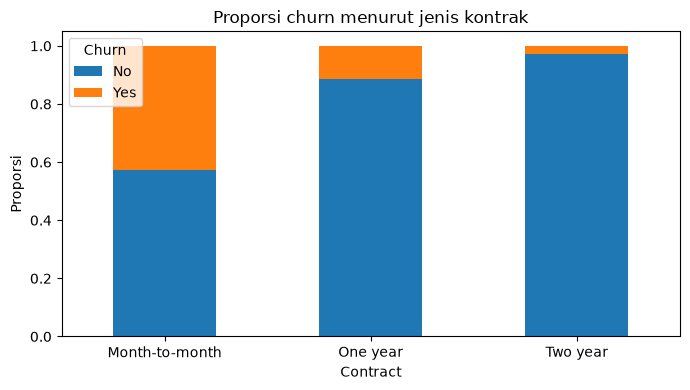

In [8]:
for fitur in ["Contract", "InternetService", "PaymentMethod"]:
    print(f"\nFrekuensi kategori {fitur}:")
    print(df[fitur].value_counts())
    print(f"Persentase churn per kategori {fitur}:")
    print((df.groupby(fitur)["Churn"].apply(lambda s: s.eq("Yes").mean()) * 100).round(2))

kontrak_churn = pd.crosstab(df["Contract"], df["Churn"], normalize="index")
kontrak_churn[["No", "Yes"]].plot(kind="bar", stacked=True, figsize=(7, 4))
plt.ylabel("Proporsi")
plt.title("Proporsi churn menurut jenis kontrak")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Dari fitur kategorikal, `Contract` memiliki hubungan terkuat dengan `Churn` pada pengukuran Cramer's V. Persentase churn pelanggan kontrak bulanan jauh lebih tinggi daripada kontrak dua tahun. Hubungan ini bersifat deskriptif dan tidak otomatis menunjukkan sebab-akibat. Semua 19 fitur asal selain `customerID` dan target tetap digunakan sebagai pembanding awal; notebook ini belum melakukan seleksi fitur berdasarkan hasil EDA.

# 2. Preprocessing

In [9]:
X = df.drop(columns=["customerID", "Churn"])
y = df["Churn"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train, y_train, test_size=0.20, stratify=y_train, random_state=RANDOM_STATE
)
print("Train penuh:", len(X_train), "| Fit:", len(X_fit),
      "| Validasi:", len(X_val), "| Test:", len(X_test))
print("Distribusi label tiap bagian:")
display(pd.DataFrame({"fit": y_fit.value_counts(),
                      "validasi": y_val.value_counts(),
                      "test": y_test.value_counts()}))

Train penuh: 5634 | Fit: 4507 | Validasi: 1127 | Test: 1409
Distribusi label tiap bagian:


,fit,validasi,test
Churn,,,
No,3311,828,1035
Yes,1196,299,374


Data dibagi secara terstratifikasi: 80% train dan 20% test. Sebagian train dipakai sebagai validasi internal untuk membandingkan eksperimen. `TotalCharges` yang kosong akan diimputasi dengan median dari data pelatihan terkait. Fitur numerik distandardisasi, sedangkan fitur kategorikal diberi one-hot encoding; `customerID` tidak dipakai karena hanya identitas.

In [10]:
def make_preprocessor():
    num_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])
    cat_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
    ])
    return ColumnTransformer([
        ("numeric", num_pipe, numeric_features),
        ("categorical", cat_pipe, categorical_features)
    ])

preprocessor = make_preprocessor()
X_fit_ready = preprocessor.fit_transform(X_fit)
X_val_ready = preprocessor.transform(X_val)
print("Dimensi sesudah preprocessing:", X_fit_ready.shape, X_val_ready.shape)
print("Jumlah NaN pada data fit:", np.isnan(X_fit_ready).sum())
print("Jumlah NaN pada data validasi:", np.isnan(X_val_ready).sum())

Dimensi sesudah preprocessing: (4507, 46) (1127, 46)
Jumlah NaN pada data fit: 0
Jumlah NaN pada data validasi: 0


Imputasi, standardisasi, dan encoding dipelajari dari bagian *fit* saja saat eksperimen. Pada model akhir, seluruh prosedur di-*fit* ulang pada seluruh data train melalui `Pipeline`.

# 3. Eksperimen Model

In [11]:
def make_mlp(activation="relu", hidden_layer_sizes=(10,), max_iter=200):
    return MLPClassifier(
        hidden_layer_sizes=hidden_layer_sizes,
        activation=activation,
        solver="adam",
        alpha=0.0001,
        max_iter=max_iter,
        random_state=RANDOM_STATE
    )

# Seluruh model eksperimen dan prediksinya disimpan di satu variabel.
res = {}
def simpan_hasil(nama, model, eksperimen):
    pred_fit = model.predict(X_fit_ready)
    pred_val = model.predict(X_val_ready)
    res[nama] = {
        "model": model,
        "eksperimen": eksperimen,
        "pred_fit": pred_fit,
        "pred_val": pred_val,
        "accuracy_fit": accuracy_score(y_fit, pred_fit),
        "accuracy_val": accuracy_score(y_val, pred_val),
        "precision_val": precision_score(y_val, pred_val, pos_label="Yes"),
        "recall_val": recall_score(y_val, pred_val, pos_label="Yes"),
        "f1_val": f1_score(y_val, pred_val, pos_label="Yes"),
        "iterasi_aktual": model.n_iter_
    }

## 3.1 ANN dengan arsitektur dasar

In [12]:
baseline = make_mlp()
baseline.fit(X_fit_ready, y_fit)
simpan_hasil("relu (10,), iter=200", baseline, "Baseline")
print("Model baseline:", baseline.activation, baseline.hidden_layer_sizes)
print("Akurasi fit/validasi:", round(res["relu (10,), iter=200"]["accuracy_fit"], 4),
      round(res["relu (10,), iter=200"]["accuracy_val"], 4))

Model baseline: relu (10,)
Akurasi fit/validasi: 0.8107 0.8181


## 3.2 Perbandingan fungsi aktivasi

In [13]:
activation_keys = {"relu": "relu (10,), iter=200"}
for aktivasi in ["tanh", "logistic"]:
    model = make_mlp(activation=aktivasi)
    model.fit(X_fit_ready, y_fit)
    nama = f"{aktivasi} (10,), iter=200"
    simpan_hasil(nama, model, "Aktivasi")
    activation_keys[aktivasi] = nama

activation_summary = pd.DataFrame([
    {
        "Aktivasi": aktivasi,
        "Accuracy Fit": res[nama]["accuracy_fit"],
        "Accuracy Validasi": res[nama]["accuracy_val"],
        "F1 Yes Validasi": res[nama]["f1_val"],
        "Iterasi Aktual": res[nama]["iterasi_aktual"]
    }
    for aktivasi, nama in activation_keys.items()
]).set_index("Aktivasi")
display(activation_summary.round(4))
best_activation = activation_summary["Accuracy Validasi"].idxmax()
print("Aktivasi terpilih:", best_activation)

,Accuracy Fit,Accuracy Validasi,F1 Yes Validasi,Iterasi Aktual
Aktivasi,,,,
relu,0.8107,0.8181,0.6293,200
tanh,0.8136,0.8092,0.5920,200
logistic,0.8067,0.8163,0.6042,183


Aktivasi terpilih: relu


Aktivasi dipilih berdasarkan accuracy validasi. ReLU unggul tipis pada pembagian data ini, sehingga dipakai untuk membandingkan ukuran arsitektur. Nilai F1 kelas `Yes` ikut ditampilkan agar dampak ketidakseimbangan kelas tetap terlihat.

## 3.3 Perbandingan ukuran arsitektur

In [14]:
architectures = [(2,), (5,), (10,), (50,), (100, 50)]
architecture_keys = {}
for arsitektur in architectures:
    if arsitektur == (10,):
        nama = activation_keys[best_activation]
    else:
        nama = f"{best_activation} {arsitektur}, iter=200"
        model = make_mlp(activation=best_activation, hidden_layer_sizes=arsitektur)
        model.fit(X_fit_ready, y_fit)
        simpan_hasil(nama, model, "Arsitektur")
    architecture_keys[arsitektur] = nama

architecture_summary = pd.DataFrame([
    {
        "Arsitektur": str(arsitektur),
        "Accuracy Fit": res[nama]["accuracy_fit"],
        "Accuracy Validasi": res[nama]["accuracy_val"],
        "F1 Yes Validasi": res[nama]["f1_val"],
        "Iterasi Aktual": res[nama]["iterasi_aktual"]
    }
    for arsitektur, nama in architecture_keys.items()
]).set_index("Arsitektur")
display(architecture_summary.round(4))
best_architecture = max(architectures,
                        key=lambda arsitektur: res[architecture_keys[arsitektur]]["accuracy_val"])
print("Arsitektur terpilih:", best_architecture)

,Accuracy Fit,Accuracy Validasi,F1 Yes Validasi,Iterasi Aktual
Arsitektur,,,,
"(2,)",0.8016,0.8172,0.6113,89
"(5,)",0.8147,0.8163,0.5996,180
"(10,)",0.8107,0.8181,0.6293,200
"(50,)",0.8405,0.7906,0.5830,200
"(100, 50)",0.9441,0.7578,0.5442,200


Arsitektur terpilih: (10,)


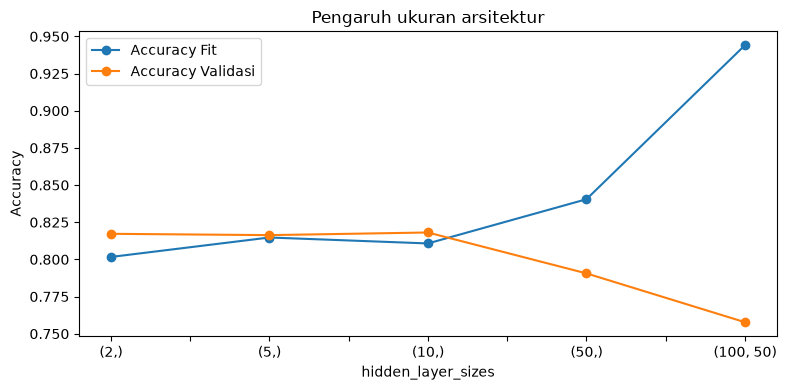

In [15]:
ax = architecture_summary[["Accuracy Fit", "Accuracy Validasi"]].plot(
    marker="o", figsize=(8, 4))
ax.set(xlabel="hidden_layer_sizes", ylabel="Accuracy",
       title="Pengaruh ukuran arsitektur")
plt.tight_layout()
plt.show()

Arsitektur besar dapat mempelajari data fit dengan lebih baik, tetapi belum tentu memberi akurasi validasi lebih tinggi. Bandingkan jarak antara kurva fit dan validasi untuk melihat gejala overfitting.

## 3.4 Pengaruh jumlah iterasi

In [16]:
iteration_values = [50, 150, 200, 300]
iteration_keys = {}
for batas_iterasi in iteration_values:
    if batas_iterasi == 200:
        nama = architecture_keys[best_architecture]
    else:
        nama = f"{best_activation} {best_architecture}, iter={batas_iterasi}"
        model = make_mlp(activation=best_activation,
                         hidden_layer_sizes=best_architecture,
                         max_iter=batas_iterasi)
        model.fit(X_fit_ready, y_fit)
        simpan_hasil(nama, model, "Iterasi")
    iteration_keys[batas_iterasi] = nama

iteration_summary = pd.DataFrame([
    {
        "max_iter": batas_iterasi,
        "Accuracy Fit": res[nama]["accuracy_fit"],
        "Accuracy Validasi": res[nama]["accuracy_val"],
        "F1 Yes Validasi": res[nama]["f1_val"],
        "Loss Akhir": res[nama]["model"].loss_curve_[-1],
        "Iterasi Aktual": res[nama]["iterasi_aktual"]
    }
    for batas_iterasi, nama in iteration_keys.items()
]).set_index("max_iter")
display(iteration_summary.round(4))
best_iter = iteration_summary["Accuracy Validasi"].idxmax()
best_key = iteration_keys[best_iter]
print("Jumlah iterasi terpilih:", best_iter)
print("Konfigurasi terpilih:", best_key)

,Accuracy Fit,Accuracy Validasi,F1 Yes Validasi,Loss Akhir,Iterasi Aktual
max_iter,,,,,
50,0.8039,0.8181,0.6168,0.4106,50
150,0.8107,0.8225,0.6310,0.3991,150
200,0.8107,0.8181,0.6293,0.3939,200
300,0.8165,0.8137,0.6023,0.3877,300


Jumlah iterasi terpilih: 150
Konfigurasi terpilih: relu (10,), iter=150


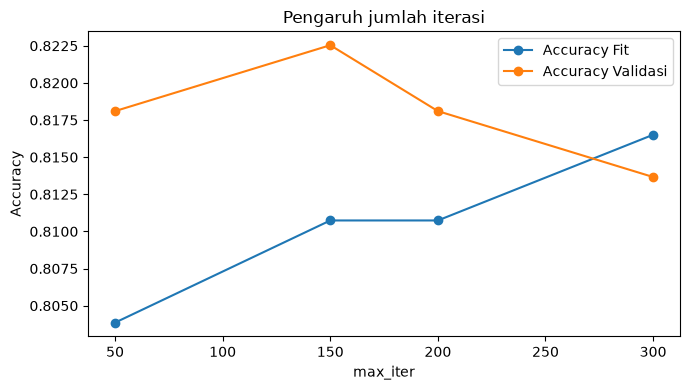

Jumlah model berbeda yang tersimpan dalam res: 10


In [17]:
ax = iteration_summary[["Accuracy Fit", "Accuracy Validasi"]].plot(
    marker="o", figsize=(7, 4))
ax.set(xlabel="max_iter", ylabel="Accuracy", title="Pengaruh jumlah iterasi")
plt.tight_layout()
plt.show()
print("Jumlah model berbeda yang tersimpan dalam res:", len(res))

Jumlah iterasi juga dipilih dari validasi, sehingga eksperimen ini benar-benar ikut menentukan konfigurasi akhir. Penurunan loss pada data fit tidak selalu diikuti peningkatan akurasi validasi.

# 4. Evaluasi Model

In [18]:
# Hanya konfigurasi yang terpilih dari validasi yang dilatih ulang pada train penuh.
model_terpilih = res[best_key]["model"]
final_model = Pipeline([
    ("preprocess", make_preprocessor()),
    ("mlp", make_mlp(
        activation=model_terpilih.activation,
        hidden_layer_sizes=model_terpilih.hidden_layer_sizes,
        max_iter=model_terpilih.max_iter
    ))
])
final_model.fit(X_train, y_train)
pred_train = final_model.predict(X_train)
pred_test = final_model.predict(X_test)
res["Final"] = {
    "model": final_model,
    "eksperimen": "Evaluasi akhir",
    "pred_train": pred_train,
    "pred_test": pred_test
}

evaluasi = pd.DataFrame([{
    "Aktivasi": model_terpilih.activation,
    "Arsitektur": str(model_terpilih.hidden_layer_sizes),
    "max_iter": model_terpilih.max_iter,
    "Accuracy Train": accuracy_score(y_train, pred_train),
    "Accuracy Test": accuracy_score(y_test, pred_test),
    "Precision Yes": precision_score(y_test, pred_test, pos_label="Yes"),
    "Recall Yes": recall_score(y_test, pred_test, pos_label="Yes"),
    "F1 Yes": f1_score(y_test, pred_test, pos_label="Yes")
}], index=["ANN terpilih"])
display(evaluasi.round(4))
print("Akurasi bila selalu memprediksi No:", round(y_test.eq("No").mean(), 4))

,Aktivasi,Arsitektur,max_iter,Accuracy Train,Accuracy Test,Precision Yes,Recall Yes,F1 Yes
ANN terpilih,relu,"(10,)",150,0.8138,0.7956,0.6327,0.5481,0.5874


Akurasi bila selalu memprediksi No: 0.7346


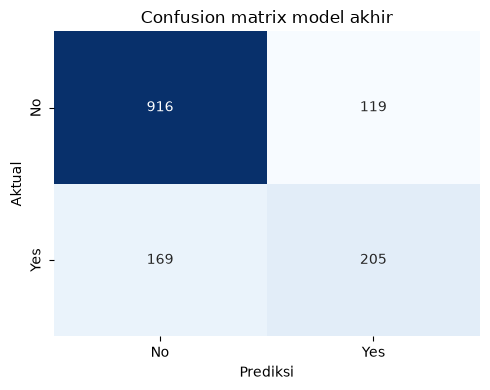

TN, FP, FN, TP: 916 119 169 205


In [19]:
cm = confusion_matrix(y_test, res["Final"]["pred_test"], labels=["No", "Yes"])
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=["No", "Yes"], yticklabels=["No", "Yes"])
plt.xlabel("Prediksi")
plt.ylabel("Aktual")
plt.title("Confusion matrix model akhir")
plt.tight_layout()
plt.show()
print("TN, FP, FN, TP:", cm[0, 0], cm[0, 1], cm[1, 0], cm[1, 1])

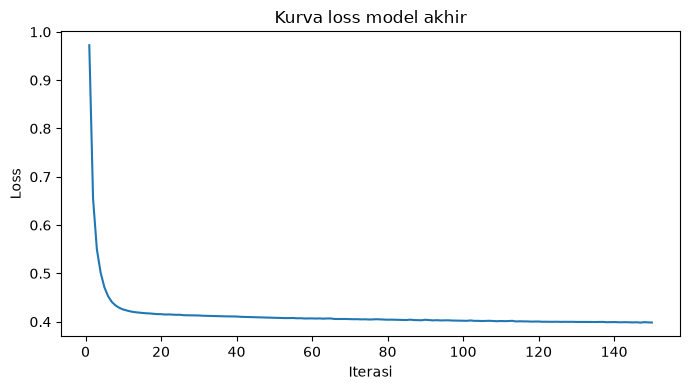

Iterasi aktual/batas: 150 / 150
Loss awal/akhir: 0.9724 0.3984


In [20]:
final_mlp = res["Final"]["model"].named_steps["mlp"]
plt.figure(figsize=(7, 4))
plt.plot(range(1, len(final_mlp.loss_curve_) + 1), final_mlp.loss_curve_)
plt.xlabel("Iterasi")
plt.ylabel("Loss")
plt.title("Kurva loss model akhir")
plt.tight_layout()
plt.show()
print("Iterasi aktual/batas:", final_mlp.n_iter_, "/", final_mlp.max_iter)
print("Loss awal/akhir:", round(final_mlp.loss_curve_[0], 4),
      round(final_mlp.loss_curve_[-1], 4))

# 5. Analisis

## 5.1 Temuan EDA dan Preprocessing

Dataset terdiri dari 7.043 pelanggan. Sebanyak 5.174 pelanggan tidak churn (73,46%) dan 1.869 churn (26,54%), sehingga kelas `Yes` lebih sedikit. Tidak ada baris duplikat secara persis. Sebelas nilai `TotalCharges` yang tampak kosong awalnya berupa string, kemudian diubah menjadi `NaN` dan diimputasi menggunakan median data pelatihan. `customerID` tidak dipakai sebagai fitur karena hanya penanda pelanggan.

Dari EDA numerik, median `tenure` pelanggan churn adalah **10 bulan**, sedangkan pelanggan yang bertahan **38 bulan**. Median `MonthlyCharges` kelas churn juga lebih tinggi (**79,65** dibandingkan **64,43**). Korelasi Spearman dengan `Churn=Yes` paling besar secara absolut ada pada `tenure` (**−0,367**). Pada fitur kategorikal, `Contract` mempunyai Cramer's V tertinggi (**0,410**). Persentase churn pada kontrak bulanan **42,71%**, jauh di atas kontrak dua tahun **2,83%**. Hubungan tiap fitur ini membantu memahami data, tetapi tidak membuktikan sebab-akibat dan tidak dipakai untuk membuang fitur secara otomatis.

Sebanyak **19 fitur asal** digunakan: tiga numerik dan 16 kategorikal. Setelah one-hot encoding terdapat **46 kolom**. Data dibagi menjadi 5.634 train dan 1.409 test; dari train, 4.507 sampel digunakan untuk fit eksperimen dan 1.127 untuk validasi. Imputasi, scaling, dan encoding pada eksperimen dipelajari dari bagian fit saja, sehingga data validasi tidak ikut menentukan statistik preprocessing.

## 5.2 Perbandingan Eksperimen Model

**Fungsi aktivasi.** Dengan arsitektur `(10,)` dan `max_iter=200`, akurasi validasi ReLU **0,8181**, Tanh **0,8092**, dan Logistic **0,8163**. ReLU terpilih, tetapi selisihnya dengan Logistic hanya **0,0018**. F1 validasi kelas `Yes` juga tertinggi pada ReLU (**0,6293**), dibandingkan Tanh **0,5920** dan Logistic **0,6042**. Hasil ini menunjukkan perbedaan pada pembagian data yang digunakan, belum keunggulan mutlak suatu aktivasi.

**Ukuran arsitektur.** Dengan ReLU, `(10,)` memberi akurasi validasi tertinggi, **0,8181**. Arsitektur `(2,)` hampir menyamai hasil tersebut (**0,8172**), walaupun jauh lebih kecil. Saat ukuran dinaikkan ke `(50,)`, akurasi fit naik menjadi **0,8405** tetapi validasi turun ke **0,7906**. Pada `(100, 50)`, perbedaannya makin besar: fit **0,9441** dan validasi **0,7578**. Pola ini menunjukkan overfitting pada arsitektur yang lebih besar dalam eksperimen ini.

**Jumlah iterasi.** Pada ReLU `(10,)`, `max_iter=150` memberi akurasi validasi tertinggi, **0,8225**, dan F1 validasi `Yes` **0,6310**. Ketika batas dinaikkan sampai 300, loss fit terus turun dari **0,3991** ke **0,3877**, tetapi akurasi validasi justru turun ke **0,8137**. Jadi, memberi waktu pelatihan lebih lama tidak otomatis memperbaiki hasil pada data di luar fit. Berbeda dari versi awal, hasil percobaan iterasi kini ikut menentukan model akhir.

## 5.3 Evaluasi Model Akhir

Konfigurasi yang dipilih dari validasi adalah **ReLU `(10,)` dengan `max_iter=150`**. Setelah dilatih ulang pada seluruh data train, model memperoleh accuracy test **0,7956**, precision `Yes` **0,6327**, recall `Yes` **0,5481**, dan F1 `Yes` **0,5874**. Accuracy ini lebih tinggi daripada prediksi selalu `No` (**0,7346**), tetapi confusion matrix menunjukkan **169 dari 374** pelanggan yang benar-benar churn masih diprediksi `No`; **205** berhasil terdeteksi. Karena distribusi kelas tidak seimbang, accuracy perlu dibaca bersama recall dan F1 kelas `Yes`.

Kurva loss model akhir turun dari **0,9724** ke **0,3984**. Model berhenti tepat pada batas 150 iterasi, sehingga penurunan loss pada data train belum dapat dinyatakan selesai. Namun, hasil eksperimen 300 iterasi menunjukkan bahwa mengejar loss train yang lebih rendah saja bukan alasan cukup untuk menambah iterasi. Angka test di atas berasal dari satu pembagian data dan sebaiknya diperiksa lagi dengan validasi silang sebelum menyimpulkan performa model secara umum.

# 6. Kesimpulan dan Saran

## Kesimpulan

1. **Pola data yang menonjol:** Pelanggan dengan `tenure` lebih pendek dan kontrak bulanan lebih sering berada pada kelas churn. `Contract` memiliki hubungan kategorikal terkuat dengan target pada EDA, sedangkan `tenure` memiliki korelasi numerik terbesar secara absolut. Semua 19 fitur asal tetap digunakan oleh model.
2. **Model yang lebih besar tidak selalu lebih baik:** ReLU dengan 10 neuron mencapai akurasi validasi **0,8181**, hampir sama dengan dua neuron (**0,8172**). Sebaliknya, arsitektur `(100, 50)` mencapai akurasi fit **0,9441** tetapi validasi hanya **0,7578**, sehingga menunjukkan overfitting.
3. **Iterasi terbaik bukan yang terbanyak:** Pada arsitektur terpilih, 150 iterasi menghasilkan akurasi validasi tertinggi (**0,8225**). Model akhir memperoleh akurasi test **0,7956** dan F1 churn **0,5874**. Walaupun lebih baik dari akurasi tebakan selalu `No` (**0,7346**), model masih melewatkan **169 dari 374** pelanggan churn pada test.

## Saran

1. **Uji komposisi dan bentuk fitur.** Notebook sudah memakai seluruh fitur asal, tetapi belum membandingkannya dengan subset fitur atau fitur baru. Coba seleksi fitur berdasarkan hubungan dengan churn dan buat interaksi yang masuk akal, misalnya antara `Contract` dan `tenure` atau jenis layanan internet dan `TechSupport`. Bandingkan hasilnya lewat validasi; hubungan satu fitur yang rendah tidak cukup sebagai alasan untuk langsung membuangnya.
2. **Perluas penalaan ANN.** Eksperimen ini baru mengubah aktivasi, ukuran layer, dan `max_iter`. Nilai `alpha`, `learning_rate_init`, `batch_size`, serta `early_stopping` belum diuji. Kombinasi tersebut berpeluang memperbaiki akurasi dan menahan overfitting yang muncul pada arsitektur besar.
3. **Periksa kestabilan hasil.** Gunakan validasi silang terstratifikasi pada data train untuk memastikan konfigurasi terbaik tidak hanya cocok pada satu pembagian validasi. Sesudah seluruh pilihan dibuat, gunakan test set sekali untuk evaluasi akhir. Jika tujuan utamanya menemukan pelanggan yang akan churn, bandingkan juga recall dan F1 `Yes` saat memilih model; peningkatan accuracy saja belum tentu mengurangi jumlah churn yang terlewat.